# TP Integrador - Aprendizaje Automatico
## Prediccion de consumo electrico de un hogar

**Entrega 2 y 3 - Preparacion, baselines, regresion y clasificacion**

Dos tareas sobre el mismo dataset (UCI *Individual Household Electric Power Consumption*):
1. **Regresion:** energia activa de las proximas 24 h (kWh).
2. **Clasificacion:** `me_paso = 1` si esas proximas 24 h superan la meta diaria.

**Tarea complementaria:** comparador estacional que compara el mes de enero de los ultimos anios y estima el enero siguiente (2011).

Momento de la prediccion: cualquier hora del dia, usando solo lo medido hasta ese instante. Meta diaria = consumo diario promedio del conjunto de entrenamiento.

In [1]:
# ============================================================
# Configuracion general
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
matplotlib.rcParams["figure.figsize"] = (10, 4)

# Carpeta raiz del proyecto (funciona si el notebook se ejecuta desde notebooks/)
BASE = Path.cwd()
if not (BASE / "datos").exists() and (BASE.parent / "datos").exists():
    BASE = BASE.parent
print("Raiz del proyecto:", BASE)

Raiz del proyecto: C:\Users\romin\Desktop\tpintegrador


In [2]:
%matplotlib inline

## 1. Carga de datos y control de calidad

El dataset original trae una medicion por minuto de un hogar en Sceaux (Francia), de diciembre 2006 a noviembre 2010. Los faltantes vienen codificados como `?`.

In [3]:
DATA = BASE / "datos" / "household_power_consumption.txt"
raw = pd.read_csv(DATA, sep=";", na_values="?", low_memory=False)

# Timestamp
raw["datetime"] = pd.to_datetime(raw["Date"] + " " + raw["Time"],
                                 format="%d/%m/%Y %H:%M:%S", errors="coerce")

num_cols = ["Global_active_power", "Global_reactive_power", "Voltage",
            "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
raw[num_cols] = raw[num_cols].apply(pd.to_numeric, errors="coerce")

print("Filas crudas:", len(raw))
print("Fechas invalidas:", raw["datetime"].isna().sum())
print("Timestamps duplicados:", raw["datetime"].duplicated().sum())
print("\nFaltantes por columna (%):")
print((raw[num_cols].isna().mean() * 100).round(2))

raw = raw.dropna(subset=["datetime"]).sort_values("datetime").set_index("datetime")
print("\nRango temporal:", raw.index.min(), "->", raw.index.max())

Filas crudas: 2075259
Fechas invalidas: 0


Timestamps duplicados: 0

Faltantes por columna (%):
Global_active_power      1.25
Global_reactive_power    1.25
Voltage                  1.25
Global_intensity         1.25
Sub_metering_1           1.25
Sub_metering_2           1.25
Sub_metering_3           1.25
dtype: float64



Rango temporal: 2006-12-16 17:24:00 -> 2010-11-26 21:02:00


In [4]:
# Valores imposibles / fuera de rango fisico
print("Voltage fuera de [180, 260]:", ((raw["Voltage"] < 180) | (raw["Voltage"] > 260)).sum())
print("Potencias negativas active:", (raw["Global_active_power"] < 0).sum())
print("Potencias negativas reactive:", (raw["Global_reactive_power"] < 0).sum())
print("Intensidad negativa:", (raw["Global_intensity"] < 0).sum())

Voltage fuera de [180, 260]: 0
Potencias negativas active: 0
Potencias negativas reactive: 0
Intensidad negativa: 0


## 2. Agregacion horaria y energia

`Global_active_power` esta en kW (promedio por minuto). La energia de una hora es `potencia_media x 1 h` = **kWh**. La reactiva (`Global_reactive_power`, en kVAr) da **kVArh**. Los submedidores vienen en Wh por minuto, por lo que se **suman** y se dividen por 1000.

Solo se conservan las horas con al menos **75%** de minutos medidos (filtro de calidad).

In [5]:
res = raw.resample("h")
count = res["Global_active_power"].count()

base = pd.DataFrame(index=count.index)
base["cobertura"] = count / 60.0
base["kwh_h"] = res["Global_active_power"].mean()          # kW medio x 1 h = kWh/h
base["kvarh_h"] = res["Global_reactive_power"].mean()      # kVArh de la hora
base["volt"] = res["Voltage"].mean()
base["sub1_kwh"] = res["Sub_metering_1"].sum() / 1000.0    # Wh -> kWh
base["sub2_kwh"] = res["Sub_metering_2"].sum() / 1000.0
base["sub3_kwh"] = res["Sub_metering_3"].sum() / 1000.0

print("Horas totales:", len(base))
base = base[base["cobertura"] >= 0.75]
print("Horas conservadas (cobertura >= 75%):", len(base))
print("Horas descartadas:", (count / 60.0 < 0.75).sum())
base = base.drop(columns="cobertura")

Horas totales: 34589
Horas conservadas (cobertura >= 75%): 34151
Horas descartadas: 438


## 3. Variables predictoras y control de fugas

**Disponibles al momento de la consulta (hora t):** energia de la ultima hora, energia de las ultimas 24 h, mismas 24 h de la semana anterior, reactiva y cos Ï† de las ultimas 24 h, submedidores de las ultimas 24 h, voltaje medio, calendario y temperatura.

**Descartadas por fuga:**
- `Global_intensity` = potencia / voltaje (objetivo disfrazado).
- Potencia, reactiva y submedidores de las horas **futuras** (son el objetivo).
- Fecha como numero continuo (no generaliza).

Cos Ï† del periodo = P / sqrt(P^2 + Q^2) con las **energias sumadas** (como factura la distribuidora).

In [6]:
h = base.copy()

h["active_24"] = h["kwh_h"].rolling(24).sum()
h["active_prevweek"] = h["kwh_h"].rolling(24).sum().shift(168)   # mismas 24 h, semana anterior
h["reactive_24"] = h["kvarh_h"].rolling(24).sum()
for s in [1, 2, 3]:
    h[f"sub{s}_24"] = h[f"sub{s}_kwh"].rolling(24).sum()
h["volt_24"] = h["volt"].rolling(24).mean()

den = np.sqrt(h["active_24"] ** 2 + h["reactive_24"] ** 2)
h["cosphi_24"] = np.where(den > 0, h["active_24"] / den, np.nan)
print("Horas:", len(h))

Horas: 34151


In [7]:
# Calendario
h["hour"] = h.index.hour
h["dayofweek"] = h.index.dayofweek
h["month"] = h.index.month
h["is_weekend"] = (h.index.dayofweek >= 5).astype(int)
feriados_fijos = {(1, 1), (5, 1), (5, 8), (7, 14), (8, 15), (11, 1), (11, 11), (12, 25)}
h["is_feriado"] = [(m, d) in feriados_fijos for m, d in zip(h.index.month, h.index.day)]

# Temperatura (Open-Meteo, archivo historico diario)
clima = pd.read_csv(BASE / "datos" / "clima_sceaux.csv", parse_dates=["date"]).set_index("date")
temp_diaria = clima["temp_mean"]
dias = h.index.normalize()
h["temp_actual"] = temp_diaria.reindex(dias).values
h["temp_next24"] = temp_diaria.reindex(dias + pd.Timedelta(days=1)).values

# Variable objetivo: energia de las proximas 24 h (t+1 .. t+24)
h["y_reg"] = h["kwh_h"].rolling(24).sum().shift(-24)
print("Filas con objetivo:", h["y_reg"].notna().sum())
h[["kwh_h", "active_24", "cosphi_24", "temp_actual", "y_reg"]].tail()

Filas con objetivo: 34127


,kwh_h,active_24,cosphi_24,temp_actual,y_reg
datetime,,,,,
2010-11-26 16:00:00,1.067933,29.850100,0.996859,0.4,NaN
2010-11-26 17:00:00,1.725900,30.095900,0.996886,0.4,NaN
2010-11-26 18:00:00,1.573467,29.457767,0.996832,0.4,NaN
2010-11-26 19:00:00,1.659333,28.786633,0.996935,0.4,NaN
2010-11-26 20:00:00,1.163700,28.302500,0.996932,0.4,NaN


### 3.1 Separacion cronologica (regla 4 y 7)

Las ventanas de 24 h se superponen: la consulta de las 19:00 y la de las 20:00 comparten 23 de 24 horas. Un split al azar filtraria el test en el entrenamiento. Por eso se separa **por tiempo**, con un **hueco de 48 h** entre bloques, y el test se reserva para el final.

In [8]:
FEATURES = ["kwh_h", "active_24", "active_prevweek", "reactive_24", "cosphi_24",
            "sub1_24", "sub2_24", "sub3_24", "volt_24",
            "hour", "dayofweek", "month", "is_weekend", "is_feriado",
            "temp_actual", "temp_next24"]

data = h.dropna(subset=FEATURES + ["y_reg"]).copy()
print("Registros utiles:", len(data), "| predictores:", len(FEATURES))

def split_cronologico(frame, frac_train=0.70, frac_val=0.15, gap=48):
    n = len(frame)
    i1 = int(n * frac_train)
    i2 = int(n * (frac_train + frac_val))
    train = frame.iloc[:i1].copy()
    val = frame.iloc[i1 + gap:i2].copy()
    test = frame.iloc[i2 + gap:].copy()
    return train, val, test

train, val, test = split_cronologico(data)
print("train:", train.index.min(), "->", train.index.max(), len(train))
print("val  :", val.index.min(), "->", val.index.max(), len(val))
print("test :", test.index.min(), "->", test.index.max(), len(test))

Registros utiles: 33936 | predictores: 16
train: 2006-12-24 17:00:00 -> 2009-09-15 09:00:00 23755
val  : 2009-09-17 10:00:00 -> 2010-04-19 01:00:00 5042
test : 2010-04-21 02:00:00 -> 2010-11-25 20:00:00 5043


In [9]:
# Meta diaria = consumo diario promedio de ENTRENAMIENTO (queda fija)
meta = train["y_reg"].mean()
print(f"Meta diaria (umbral): {meta:.3f} kWh")

for nombre, sub in [("train", train), ("val", val), ("test", test)]:
    sub["me_paso"] = (sub["y_reg"] > meta).astype(int)
    print(f"{nombre}: me_paso=1 -> {sub['me_paso'].mean()*100:.1f}%")

Meta diaria (umbral): 25.918 kWh
train: me_paso=1 -> 48.3%
val: me_paso=1 -> 72.4%
test: me_paso=1 -> 33.7%


## 4. Baselines (DummyRegressor y DummyClassifier)

Todo modelo debe compararse contra un baseline tonto. La regla de oro del problema es el **baseline estacional** de la tarea complementaria: 'manana consumo lo mismo que hace un ano'.

In [10]:
X_train, y_train = train[FEATURES], train["y_reg"]
X_val, y_val = val[FEATURES], val["y_reg"]
X_test, y_test = test[FEATURES], test["y_reg"]

clf_train, clf_val, clf_test = train["me_paso"], val["me_paso"], test["me_paso"]

def metricas_reg(y, yp):
    return {"MAE": mean_absolute_error(y, yp),
            "RMSE": np.sqrt(mean_squared_error(y, yp)),
            "R2": r2_score(y, yp)}

dummy_reg = DummyRegressor(strategy="mean").fit(X_train, y_train)
print("DummyRegressor (validacion):", {k: round(v, 3) for k, v in metricas_reg(y_val, dummy_reg.predict(X_val)).items()})

dummy_clf = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE).fit(X_train, clf_train)
pc = dummy_clf.predict(X_val)
print("DummyClassifier (validacion): acc=%.3f prec=%.3f rec=%.3f f1=%.3f" % (
    accuracy_score(clf_val, pc), precision_score(clf_val, pc, zero_division=0),
    recall_score(clf_val, pc, zero_division=0), f1_score(clf_val, pc, zero_division=0)))

DummyRegressor (validacion): {'MAE': 6.386, 'RMSE': np.float64(8.241), 'R2': -0.337}
DummyClassifier (validacion): acc=0.501 prec=0.732 rec=0.489 f1=0.586


## 5. Regresion: energia de las proximas 24 h

Se comparan los modelos obligatorios: DummyRegressor, DecisionTreeRegressor y KNeighborsRegressor con StandardScaler dentro de un Pipeline. Se prueban distintas profundidades y valores de k, y se elige con **validacion** (nunca con el test).

In [11]:
candidatos_reg = {"DummyRegressor(media)": DummyRegressor(strategy="mean")}
for depth in [3, 5, 8, 12, None]:
    candidatos_reg[f"DecisionTree depth={depth}"] = DecisionTreeRegressor(
        max_depth=depth, random_state=RANDOM_STATE)
for k in [5, 15, 25]:
    candidatos_reg[f"KNN k={k}"] = Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=k, n_jobs=-1))])

filas = []
for nombre, modelo in candidatos_reg.items():
    modelo.fit(X_train, y_train)
    filas.append({"modelo": nombre, **metricas_reg(y_val, modelo.predict(X_val))})
reg_tabla = pd.DataFrame(filas).sort_values("MAE").reset_index(drop=True)
best_reg_name = reg_tabla.iloc[0]["modelo"]
print(reg_tabla.round(3).to_string(index=False))

                 modelo   MAE   RMSE     R2
               KNN k=25 5.831  7.727 -0.175
   DecisionTree depth=3 5.838  7.530 -0.116
   DecisionTree depth=5 5.973  7.920 -0.235
               KNN k=15 6.116  8.143 -0.305
   DecisionTree depth=8 6.283  8.843 -0.539
  DummyRegressor(media) 6.386  8.241 -0.337
  DecisionTree depth=12 6.746  9.618 -0.821
                KNN k=5 6.946  9.383 -0.733
DecisionTree depth=None 7.936 10.846 -1.315


Mejor regresor: KNN k=25
Test: {'MAE': 4.57, 'RMSE': np.float64(6.06), 'R2': 0.308}

Residuos: media=-0.653  desvio=6.025  p5=-10.06  p95=8.72


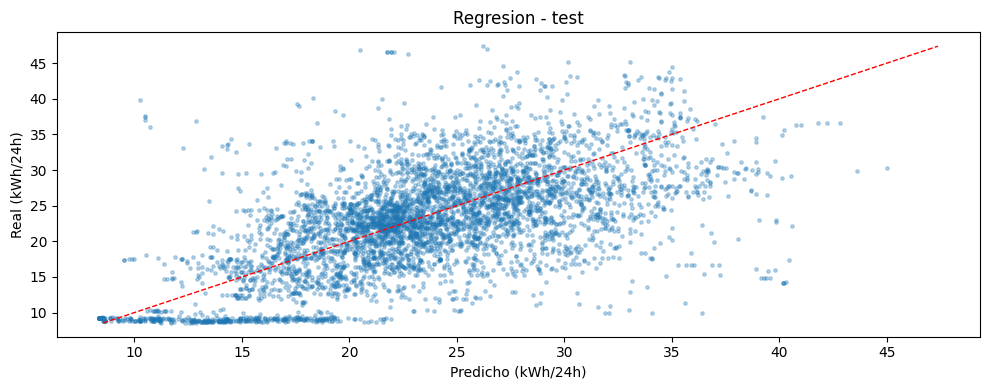

In [12]:
# Reentreno del mejor con train + validacion y evaluacion final en test
best_reg = candidatos_reg[best_reg_name]
X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])
best_reg.fit(X_trval, y_trval)

pred_test = best_reg.predict(X_test)
reg_test = metricas_reg(y_test, pred_test)
print("Mejor regresor:", best_reg_name)
print("Test:", {k: round(v, 3) for k, v in reg_test.items()})

residuos = y_test - pred_test
print("\nResiduos: media=%.3f  desvio=%.3f  p5=%.2f  p95=%.2f" % (
    residuos.mean(), residuos.std(), residuos.quantile(0.05), residuos.quantile(0.95)))

fig, ax = plt.subplots()
ax.scatter(pred_test, y_test, s=6, alpha=0.3)
lim = [y_test.min(), y_test.max()]
ax.plot(lim, lim, "r--", lw=1)
ax.set_xlabel("Predicho (kWh/24h)"); ax.set_ylabel("Real (kWh/24h)")
ax.set_title("Regresion - test"); plt.tight_layout(); plt.show()

## 6. Clasificacion: me paso de la meta

Modelos obligatorios: DummyClassifier, DecisionTreeClassifier, KNeighborsClassifier (Pipeline + StandardScaler) y GaussianNB. Metricas: accuracy, precision, recall, F1 y matriz de confusion.

In [13]:
candidatos_clf = {"DummyClassifier(estratificado)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)}
for depth in [3, 5, 8, 12, None]:
    candidatos_clf[f"DecisionTree depth={depth}"] = DecisionTreeClassifier(
        max_depth=depth, random_state=RANDOM_STATE)
for k in [5, 15, 25]:
    candidatos_clf[f"KNN k={k}"] = Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k, n_jobs=-1))])
candidatos_clf["GaussianNB"] = GaussianNB()

def metricas_clf(y, yp):
    return {"accuracy": accuracy_score(y, yp),
            "precision": precision_score(y, yp, zero_division=0),
            "recall": recall_score(y, yp, zero_division=0),
            "f1": f1_score(y, yp, zero_division=0)}

filas = []
for nombre, modelo in candidatos_clf.items():
    modelo.fit(X_train, clf_train)
    filas.append({"modelo": nombre, **metricas_clf(clf_val, modelo.predict(X_val))})
clf_tabla = pd.DataFrame(filas).sort_values("f1", ascending=False).reset_index(drop=True)
best_clf_name = clf_tabla.iloc[0]["modelo"]
print(clf_tabla.round(3).to_string(index=False))

                        modelo  accuracy  precision  recall    f1
                    GaussianNB     0.757      0.768   0.951 0.850
          DecisionTree depth=5     0.758      0.778   0.932 0.848
          DecisionTree depth=3     0.765      0.798   0.904 0.847
          DecisionTree depth=8     0.733      0.771   0.897 0.829
                      KNN k=25     0.739      0.799   0.855 0.826
                      KNN k=15     0.726      0.793   0.842 0.816
                       KNN k=5     0.699      0.786   0.803 0.794
         DecisionTree depth=12     0.690      0.775   0.806 0.790
       DecisionTree depth=None     0.638      0.771   0.710 0.739
DummyClassifier(estratificado)     0.501      0.732   0.489 0.586


In [14]:
best_clf = candidatos_clf[best_clf_name]
clf_trval = pd.concat([clf_train, clf_val])
best_clf.fit(X_trval, clf_trval)
pred_clf_test = best_clf.predict(X_test)
print("Mejor clasificador:", best_clf_name)
print({k: round(v, 3) for k, v in metricas_clf(clf_test, pred_clf_test).items()})
print("\nMatriz de confusion (filas=real, col=predicho):")
print(confusion_matrix(clf_test, pred_clf_test))

Mejor clasificador: GaussianNB
{'accuracy': 0.74, 'precision': 0.611, 'recall': 0.629, 'f1': 0.62}

Matriz de confusion (filas=real, col=predicho):
[[2666  680]
 [ 630 1067]]


## 7. Integracion: clasificador directo vs regresion + umbral

Mismos casos de test para ambos sistemas:

| Sistema | Procedimiento |
|---|---|
| Clasificador directo | predice 0/1 directamente |
| Regresion + umbral | predice kWh y luego aplica `> meta` |

Esquema de costos 3:1 - un **falso negativo** (dijo 'no te pasas' y se paso) cuesta 3 veces mas que un **falso positivo** (dijo 'te pasas' y no se paso), porque el exceso se paga a precio pleno y agrava el recargo por cos Ï†.

In [15]:
alerta_reg = (best_reg.predict(X_test) > meta).astype(int)
alerta_clf = best_clf.predict(X_test)
y_true = clf_test.values

def sistema(y, yp):
    tn, fp, fn, tp = confusion_matrix(y, yp).ravel()
    return {"accuracy": accuracy_score(y, yp),
            "precision": precision_score(y, yp, zero_division=0),
            "recall": recall_score(y, yp, zero_division=0),
            "f1": f1_score(y, yp, zero_division=0),
            "FP": fp, "FN": fn, "costo (3*FN+FP)": 3 * fn + fp}

integradora = pd.DataFrame({
    "Clasificador directo": sistema(y_true, alerta_clf),
    "Regresion + umbral": sistema(y_true, alerta_reg),
}).T
print(integradora.round(3).to_string())

                      accuracy  precision  recall     f1     FP     FN  costo (3*FN+FP)
Clasificador directo     0.740      0.611   0.629  0.620  680.0  630.0           2570.0
Regresion + umbral       0.741      0.614   0.621  0.617  662.0  644.0           2594.0


In [16]:
# Casos cercanos al umbral = zona gris
mae_test = reg_test["MAE"]
cerca = (best_reg.predict(X_test) - meta).__abs__() <= mae_test
desacuerdo = (alerta_clf != alerta_reg)
print(f"Zona gris (|pred - meta| <= MAE={mae_test:.2f}): {cerca.mean()*100:.1f}% de los casos")
print(f"Desacuerdos entre sistemas: {desacuerdo.sum()} ({desacuerdo.mean()*100:.1f}%)")
print(f"De esos desacuerdos, {100*(cerca & desacuerdo).sum()/max(desacuerdo.sum(),1):.0f}% cae en la zona gris")

Zona gris (|pred - meta| <= MAE=4.57): 53.3% de los casos
Desacuerdos entre sistemas: 828 (16.4%)
De esos desacuerdos, 84% cae en la zona gris


## 8. Tarea complementaria - comparador estacional de enero

Objetivo: comparar el gasto del mes de **enero** de los ultimos anios y estimar el **enero de 2011** (el siguiente al dataset, que termina el 26/11/2010).

Se trabaja a nivel **diario** con variables de calendario y un rezago largo:
- `kwh_year_ago`: consumo del **mismo dia del anio anterior** (disponible al predecir).
- `month`, `doy`, `dayofweek`, `is_weekend`.

No se usan rezagos cortos (ayer / semana pasada) porque para enero 2011 no hay diciembre 2010 medido.

**Validacion:** se entrena con todo lo anterior a enero 2010 y se valida en **enero 2010**, comparando contra dos baselines: DummyRegressor y el **estacional ingenuo** (repetir el mismo dia del ano anterior).

In [17]:
# Serie diaria (min 20 horas validas por dia)
daily = pd.DataFrame({
    "kwh_day": base["kwh_h"].resample("D").sum(min_count=20),
})
daily = daily.join(temp_diaria.rename("temp_mean"))
idx = daily.index
daily["month"] = idx.month
daily["doy"] = idx.dayofyear
daily["dayofweek"] = idx.dayofweek
daily["is_weekend"] = (idx.dayofweek >= 5).astype(int)
daily["kwh_year_ago"] = daily["kwh_day"].reindex(idx - pd.DateOffset(years=1)).values

SEAS_FEAT = ["month", "doy", "dayofweek", "is_weekend", "kwh_year_ago"]
seas = daily.dropna(subset=SEAS_FEAT + ["kwh_day"]).copy()
print("Dias utiles:", len(seas), "| rango:", seas.index.min().date(), "->", seas.index.max().date())

Dias utiles: 1051 | rango: 2007-12-17 -> 2010-11-26


In [18]:
cut = pd.Timestamp("2010-01-01")
fin = pd.Timestamp("2010-02-01")
s_tr = seas[seas.index < cut]
s_val = seas[(seas.index >= cut) & (seas.index < fin)]
print("train:", len(s_tr), "| validacion (enero 2010):", len(s_val))

cand_seas = {"DummyRegressor(media)": DummyRegressor(strategy="mean"),
             "Regresion lineal": LinearRegression(),
             "DecisionTree depth=5": DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
             "KNN k=5": Pipeline([("scaler", StandardScaler()),
                                  ("model", KNeighborsRegressor(n_neighbors=5))])}

res = []
for nombre, m in cand_seas.items():
    m.fit(s_tr[SEAS_FEAT], s_tr["kwh_day"])
    res.append({"modelo": nombre, **metricas_reg(s_val["kwh_day"], m.predict(s_val[SEAS_FEAT]))})

# Baseline estacional ingenuo: mismo dia del anio anterior
res.append({"modelo": "Estacional ingenuo (ano anterior)",
            **metricas_reg(s_val["kwh_day"], s_val["kwh_year_ago"])})

seas_tabla = pd.DataFrame(res).sort_values("MAE").reset_index(drop=True)
best_seas_name = seas_tabla.iloc[0]["modelo"]
print("Mejor modelo estacional:", best_seas_name)
print(seas_tabla.round(3).to_string(index=False))

train: 739 | validacion (enero 2010): 28
Mejor modelo estacional: KNN k=5
                           modelo    MAE   RMSE     R2
                          KNN k=5  5.216  7.592 -0.377
             DecisionTree depth=5  6.478  7.877 -0.482
                 Regresion lineal  7.412  9.068 -0.964
            DummyRegressor(media)  8.853 10.351 -1.559
Estacional ingenuo (ano anterior) 10.336 12.190 -2.550


In [19]:
# Reentreno con todo el historico y pronostico de enero 2011
best_seas = cand_seas.get(best_seas_name)
if best_seas is None:  # si gana el estacional ingenuo, se usa ese como modelo
    best_seas = None
if best_seas is not None:
    best_seas.fit(seas[SEAS_FEAT], seas["kwh_day"])

fut = pd.date_range("2011-01-01", "2011-01-31")
jan11 = pd.DataFrame(index=fut)
jan11["month"] = fut.month
jan11["doy"] = fut.dayofyear
jan11["dayofweek"] = fut.dayofweek
jan11["is_weekend"] = (fut.dayofweek >= 5).astype(int)
jan11["kwh_year_ago"] = seas["kwh_day"].reindex(fut - pd.DateOffset(years=1)).values
# Si falta el mismo dia del ano anterior, se usa el promedio diario de enero
enero_medio = seas[seas.index.month == 1]["kwh_day"].mean()
jan11["kwh_year_ago"] = jan11["kwh_year_ago"].fillna(enero_medio)

rmse_val_seas = seas_tabla.loc[0, "RMSE"]
if best_seas is None:
    jan11["pred"] = jan11["kwh_year_ago"]
else:
    jan11["pred"] = best_seas.predict(jan11[SEAS_FEAT])

pred_jan11 = jan11["pred"].sum()
rmse_mes = rmse_val_seas * np.sqrt(len(jan11))
print(f"Enero 2011 estimado: {pred_jan11:.1f} kWh (+/- {rmse_mes:.1f} kWh)")
print(jan11[["pred", "kwh_year_ago"]].round(2).to_string())

Enero 2011 estimado: 1074.5 kWh (+/- 42.3 kWh)
             pred  kwh_year_ago
2011-01-01  39.73         20.40
2011-01-02  37.38         21.87
2011-01-03  27.11         34.72
2011-01-04  33.83         26.74
2011-01-05  37.09         37.00
2011-01-06  31.37         29.62
2011-01-07  33.37         29.49
2011-01-08  41.88         29.95
2011-01-09  42.39         38.95
2011-01-10  27.41         41.81
2011-01-11  35.39         25.31
2011-01-12  33.25         34.37
2011-01-13  28.34         34.37
2011-01-14  34.88         34.37
2011-01-15  42.64         36.61
2011-01-16  43.86         35.84
2011-01-17  27.07         31.78
2011-01-18  35.35         31.35
2011-01-19  31.27         40.56
2011-01-20  29.73         39.20
2011-01-21  34.27         35.63
2011-01-22  41.88         29.84
2011-01-23  33.82         43.52
2011-01-24  28.92         37.82
2011-01-25  35.93         32.18
2011-01-26  33.25         34.46
2011-01-27  27.42         46.02
2011-01-28  34.27         35.17
2011-01-29  45.28        

In [20]:
TARIFA = 150.0  # $/kWh asumida (editable desde la app)

# Totales reales de enero por anio (se usa la serie diaria completa, incluye 2007)
m1 = daily[daily.index.month == 1]
eneros = m1.groupby(m1.index.year)["kwh_day"].agg(["count", "sum"])
eneros.columns = ["dias", "kwh"]
eneros["kwh_dia"] = eneros["kwh"] / eneros["dias"]
eneros["costo_$"] = eneros["kwh"] * TARIFA
eneros = eneros.astype({"dias": int})

resumen = eneros.copy()
resumen.loc[2011] = [len(jan11), pred_jan11, pred_jan11 / len(jan11), pred_jan11 * TARIFA]
resumen["var_%"] = resumen["kwh_dia"].pct_change() * 100
resumen = resumen[["dias", "kwh", "kwh_dia", "costo_$", "var_%"]]
resumen.index.name = "anio"
print("Tarifa asumida: %.0f $/kWh" % TARIFA)
print("2011 es estimado; var_% se calcula sobre el consumo diario promedio (kwh_dia).")
print(resumen.round(2).to_string())

Tarifa asumida: 150 $/kWh
2011 es estimado; var_% se calcula sobre el consumo diario promedio (kwh_dia).
      dias      kwh  kwh_dia    costo_$  var_%
anio                                          
2007  31.0  1150.30    37.11  172544.96    NaN
2008  31.0  1086.22    35.04  162932.94  -5.57
2009  31.0  1049.22    33.85  157383.24  -3.41
2010  28.0   958.08    34.22  143711.80   1.10
2011  31.0  1074.49    34.66  161172.93   1.30


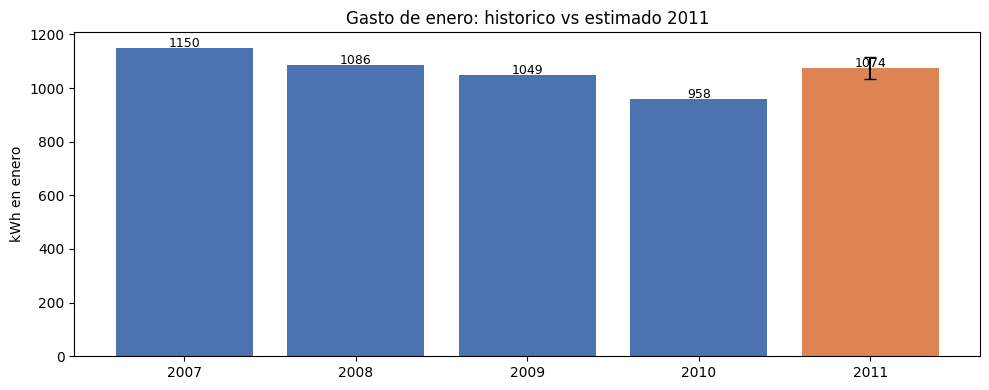

In [21]:
fig, ax = plt.subplots()
colores = ["#4C72B0"] * (len(resumen) - 1) + ["#DD8452"]
ax.bar(resumen.index.astype(str), resumen["kwh"], color=colores)
ax.errorbar(str(2011), pred_jan11, yerr=rmse_mes, fmt="none", ecolor="black", capsize=4)
ax.set_ylabel("kWh en enero"); ax.set_title("Gasto de enero: historico vs estimado 2011")
for i, (idx_, row) in enumerate(resumen.iterrows()):
    ax.text(i, row["kwh"] + 4, f"{row['kwh']:.0f}", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

## 9. Guardado de artefactos

Se guardan los Pipelines ya entrenados (no se reentrena en la app) y la lista de variables y el umbral.

In [22]:
modelos_dir = BASE / "modelos"
modelos_dir.mkdir(exist_ok=True)

joblib.dump({"modelo": best_reg, "features": FEATURES, "meta": meta,
             "nombre": best_reg_name, "mae": reg_test["MAE"], "rmse": reg_test["RMSE"]},
            modelos_dir / "reg_24h.pkl")
joblib.dump({"modelo": best_clf, "features": FEATURES, "meta": meta,
             "nombre": best_clf_name}, modelos_dir / "clf_me_paso.pkl")
joblib.dump({"modelo": best_seas, "features": SEAS_FEAT, "nombre": best_seas_name,
             "tarifa_default": TARIFA, "rmse_mes": rmse_mes},
            modelos_dir / "reg_estacional.pkl")

# Tablas del comparador estacional para la app
resumen.to_csv(modelos_dir / "enero_resumen.csv")
jan11[["pred", "kwh_year_ago"]].to_csv(modelos_dir / "enero2011_diario.csv")

# Compatibilidad con la Entrega 2 (baselines)
joblib.dump(dummy_reg, modelos_dir / "dummy_reg.pkl")
joblib.dump(dummy_clf, modelos_dir / "dummy_clf.pkl")

print("Modelos guardados en", modelos_dir)
print(sorted(p.name for p in modelos_dir.iterdir()))

Modelos guardados en C:\Users\romin\Desktop\tpintegrador\modelos
['clf_me_paso.pkl', 'dummy_clf.pkl', 'dummy_reg.pkl', 'enero2011_diario.csv', 'enero_resumen.csv', 'reg_24h.pkl', 'reg_estacional.pkl']


## 10. Conclusiones y limitaciones

- El mejor regresor se compara contra el DummyRegressor y, en la tarea estacional, contra el baseline estacional ingenuo.
- El MAE se traduce al contexto: equivocarse +/- X kWh por dia equivale a +/- $Y con la tarifa asumida.
- Los desacuerdos entre el clasificador directo y la regresion + umbral se concentran cerca del umbral (zona gris).
- **Limitaciones:** un solo hogar (Sceaux, Francia 2006-2010); solo hay **4 eneros completos**, por lo que el pronostico de un mes entero es de baja confianza y se reporta con su rango de error; la temperatura se usa como valor real (simplificacion declarada); el costo en pesos depende de una tarifa asumida, no del dataset.
- **No usar** para otro hogar sin reentrenar, ni para reclamar formalmente un recargo (vale la medicion de la distribuidora).